In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#Import the necessary libraries for data manipulation and visualization. 


In [4]:
import os 
print(os.listdir('../data/processed'))
#List the files in the processed data directory to verify that the cleaned dataset is available for analysis.

['credit_risk_dataset_cleaned.csv']


In [6]:
df = pd.read_csv('../data/processed/credit_risk_dataset_cleaned.csv')
#Load the processed credit risk dataset into a pandas DataFrame for analysis.
df.shape 
#Check the shape of the DataFrame to understand the number of rows and columns in the dataset.

(32409, 14)

In [7]:
df.head()
#Confirm that the dataset has been loaded correctly by displaying the first few rows of the DataFrame.

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,int_rate_missing
0,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,0,0
1,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,0,0
2,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,0,0
3,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,0,0
4,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2,0,0


Now the overall default rate will be checked as the start of my EDA

In [10]:
print(df['loan_status'].value_counts())
#See how many loans defaulted 
print(df['loan_status'].value_counts(normalize=True) * 100)
#See the percentage of loans that defaulted

loan_status
0    25321
1     7088
Name: count, dtype: int64
loan_status
0    78.129532
1    21.870468
Name: proportion, dtype: float64


From 32,409 loans, 78% did not default and 22% did. 

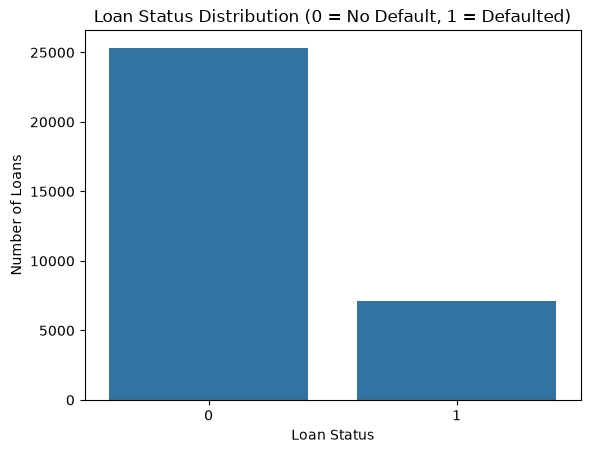

In [12]:
sns.countplot(x='loan_status', data=df)
#Bar chart to visualize the distribution of loan statuses (defaulted vs. not defaulted) in the dataset.
plt.title('Loan Status Distribution (0 = No Default, 1 = Defaulted)')
#The title of the bar chart indicates that 0 represents loans that did not default and 1 represents loans that defaulted.
plt.xlabel('Loan Status')
plt.ylabel('Number of Loans')
#Label the x-axis as 'Loan Status' and the y-axis as 'Number of Loans' to provide context for the bar chart.
plt.show()
#Display the bar chart to visualize the distribution of loan statuses in the dataset.


The Bar chart shows that of 32,409 loans, 25,321 (78.1%) did not default and 7,088 (21.9%) did 

In [13]:
default_by_prior = df.groupby('cb_person_default_on_file')['loan_status'].mean() * 100
print(default_by_prior)
#Calculate the percentage of loans that defaulted based on whether the borrower had a prior default on file and print the results to understand the relationship between prior defaults and loan default rates. 

cb_person_default_on_file
N    18.437031
Y    37.860010
Name: loan_status, dtype: float64


This means that from the borrowers with no previous loan default, 18.43% defaulted on their current loan, whereas from the borrowers that did have a porevious loan default, 37.86% defaulted again.
Applicants with a prior default are about twice as likely to default again

In [14]:
print(df.groupby('cb_person_default_on_file')['loan_status'].agg(['mean', 'count']))
#Show the default rate and the number of loans for each category of prior default status to provide additional context for the analysis of the relationship between prior defaults and loan default rates.

                              mean  count
cb_person_default_on_file                
N                          0.18437  26680
Y                          0.37860   5729


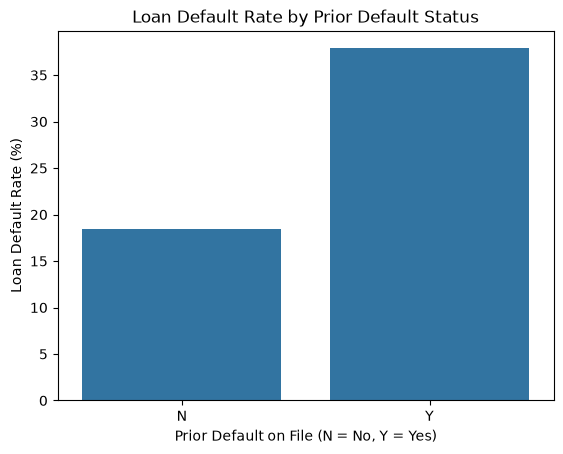

In [15]:
sns.barplot(x=default_by_prior.index, y=default_by_prior.values)
#Bar chart to visualize the relationship between prior default status and loan default rates.
plt.title('Loan Default Rate by Prior Default Status')
#The title of the bar chart indicates that it shows the loan default rate based on whether the borrower had a prior default on file.
plt.xlabel('Prior Default on File (N = No, Y = Yes)')
plt.ylabel('Loan Default Rate (%)')
#Label the x-axis as 'Prior Default on File (N = No, Y = Yes)' and the y-axis as 'Loan Default Rate (%)' to provide context for the bar chart.

plt.show()

This Bar chart compares borrowers with a prior default on file (Y) and those without (N). The number of borrowers with a prior default is roughly double the rate, supporting the idea that a prior default is associated with a higher likelihood of default. Note that this suggests association and not cause. The (Y) group (5729) is smaller than the (N) (26680) group, so it's rate is based of fewer loans, but the gap is large enough to be meaningful. 

Next, loan to income will be compared for default

In [16]:
print(df.groupby('loan_status')['loan_percent_income'].agg(['mean', 'median']))
#Compare the mean and median loan percent income for defaulted and non-defaulted loans to understand how this feature relates to loan default rates.

                 mean  median
loan_status                  
0            0.148803    0.13
1            0.246858    0.24


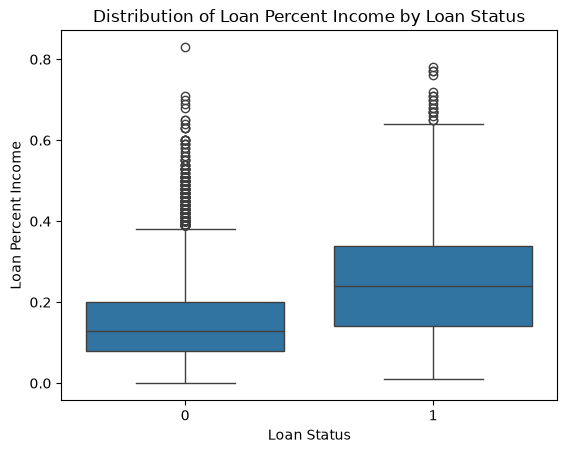

In [ ]:
sns.boxplot(x='loan_status', y='loan_percent_income', data=df)
#Box plot to visualize the distribution of loan percent income for defaulted and non-defaulted loans.
plt.xlabel('Loan Status')
plt.ylabel('Loan Percent Income')
#Label the x-axis as 'Loan Status' and the y-axis as 'Loan Percent Income' to provide context for the box plot.
plt.title('Distribution of Loan Percent Income by Loan Status')
plt.show()  

The loan default box (1) sits higher on the chart and is taller, which means defaulters borrow a larger share of their income. The two boxes overlap a bit so the groups are not totally seperatated by the ratio. The dots above the box are loans that defaulted, with an unusally high ratio for the defaulted group, but fewer than the no default group. 

The no loan default box (0) has a long line of dots going to around 0.7, which are loans that were repaid. They have a unusually high loan-to-income ratio for the repaid group. 

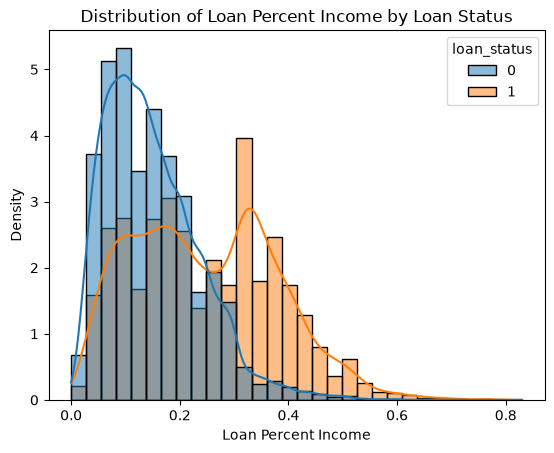

In [18]:
sns.histplot(data=df, x='loan_percent_income', hue='loan_status', bins=30,kde=True, stat='density', common_norm=False)
#Overlapping histograms to visualize the distribution of loan percent income for defaulted and non-defaulted loans, with kernel density estimation (KDE) curves to show the underlying distribution.
plt.title('Distribution of Loan Percent Income by Loan Status')
plt.xlabel('Loan Percent Income')
plt.ylabel('Density')
plt.show()
#The title of the histogram indicates that it shows the distribution of loan percent income based on loan status, with the x-axis labeled as 'Loan Percent Income' and the y-axis labeled as 'Density' to provide context for the visualization.

The blue bars are no default borrowers and the chart shows a sharp peak at 0.1 which falls and almost dissapears by 0.4. This shows most repaid loans take a small share of the borrowers income. 
The orange bars are loan default borrowers which peaks at around 0.3 and clearly dominates blue thereafter. This shows that large loans relative to income are mostly defaults.
The orange line at low ratios means that plenty of defaults happen at low ratios too, so ratio cannot soley predict defaults alone. 
The y-axis is density not amount, meaning the orange bar peak at 0.3 does not mean more defaults than not in terms of numbers, but that defaulters are much more conecntrated that non-defaulters. 

The next lines of code will work to show whether the type of loan a borrower takes and their housing situation, is linked to how often they default

In [19]:
print(df.groupby('loan_intent')['loan_status'].mean().sort_values(ascending=False) * 100)
#Calculate the percentage of loans that defaulted based on the loan intent and print the results to understand how the purpose of the loan relates to loan default rates.
print(df.groupby(('person_home_ownership'))['loan_status'].mean().sort_values(ascending=False) * 100)
#Calculate the percentage of loans that defaulted based on the borrower's home ownership status and print the results to understand how home ownership relates to loan default rates.

loan_intent
DEBTCONSOLIDATION    28.676045
MEDICAL              26.762661
HOMEIMPROVEMENT      26.154702
PERSONAL             19.887191
EDUCATION            17.256982
VENTURE              14.861771
Name: loan_status, dtype: float64
person_home_ownership
RENT        31.611091
OTHER       31.132075
MORTGAGE    12.621577
OWN          7.491221
Name: loan_status, dtype: float64


The data under loan intent show the default rate based on loan purpose. Debt consolidation defaults about twice as much as venture, showing that purpose matters. 

As can be seen under home ownership, renters default around four times as much as owners

In [20]:
print(df['person_home_ownership'].value_counts())
#See how many borrowers have each type of home ownership status to understand the distribution of this feature

person_home_ownership
RENT        16374
MORTGAGE    13366
OWN          2563
OTHER         106
Name: count, dtype: int64


Though 'other' default 31%, it is only based of a group of 106 borrowers, a very small sample. Rent, mortgage and own are much larger, so best to focus on that.

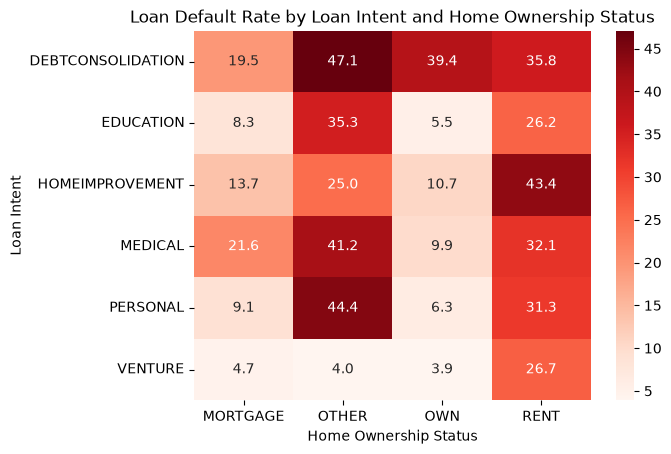

In [21]:
default_grid = df.pivot_table(values='loan_status', index='loan_intent', columns='person_home_ownership', aggfunc='mean') * 100
#Build a table to show the percentage of loans that defaulted based on both loan intent and home ownership status to understand how these two features interact in relation to loan default rates.
sns.heatmap(default_grid, annot=True, fmt='.1f', cmap='Reds')
#Heatmap to visualize the relationship between loan intent, home ownership status, and loan default rates, with annotations showing the percentage of loans that defaulted for each combination of features.
plt.title('Loan Default Rate by Loan Intent and Home Ownership Status')
plt.xlabel('Home Ownership Status')
plt.ylabel('Loan Intent')
#Label the x-axis as 'Home Ownership Status' and the y-axis as 'Loan Intent' to provide context for the heatmap.
plt.show()

The 'RENT' column is dark throughout from 26.2% in education to 43.4% in HOME IMPROVEMENT. This shows that renters largely default independent of what the loan is for. 
'MORTGAGE' and 'OWN' are quite light all around, with EDUCATION, PERSONAL and VENTURE under 10% in both columns. 

DEBT CONSOLIDATION is high across every housing type with its lowest being 19.5% in 'MORTGAGE' and the highest 47.1% in 'OTHER'. This suggests it is the purpose with the largest effect. It even stays high amongst homeowners with a 39.4% default rate. 

VENTURE loans are very low for mortage and owners (4.7%) and (3.9%) but 26.7% for renters, suggesting that it's risk is more so based on housing. 
It is also important to note that though the 'OTHER' column is very dark throughout with 25% to 47.1% for most of the loans types, it is only based on 106 loans in total, so each loan type holds very few. 

Next, the model will be tested without loan grade and loan interest rate 

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('../data/processed/credit_risk_dataset_cleaned.csv')
df.shape
#Check the shape of the DataFrame to understand the number of rows and columns in the dataset.

(32409, 14)

In [5]:
default_by_grade = df.groupby('loan_grade')['loan_status'].mean().sort_index()* 100
print(default_by_grade)
#Calculate the percentage of loans that defaulted based on the loan grade

loan_grade
A     9.960755
B    16.323190
C    20.758235
D    59.049461
E    64.485981
F    70.539419
G    98.437500
Name: loan_status, dtype: float64


Default rate rises steadily as the grade worsens. 
There is a big jump from grade C to D from 20.8% to 59%, nearly tripling. 
Grade G is almost all defaults with 98.4%. 

In [8]:
grade_summary = df.groupby('loan_grade')['loan_status'].agg(['mean', 'count'])
#Display the summary statistics for each loan grade 
grade_summary['mean'] = grade_summary['mean'] * 100
#Convert the mean default rate to a percentage for better interpretability.
grade_summary.columns = ['default_rate_(%)', 'loan_count']
#Rename the columns of the summary DataFrame to provide clear and descriptive labels for the default rate and loan count.
print(grade_summary)

            default_rate_(%)  loan_count
loan_grade                              
A                   9.960755       10702
B                  16.323190       10384
C                  20.758235        6436
D                  59.049461        3619
E                  64.485981         963
F                  70.539419         241
G                  98.437500          64


- Grades A to D are reliable figures as they rest on thousands of loans. 
- Grades E and F are much less so therefore less precise but still clear. 
- Grade G only has 64 loans with 98% being only about 63 of the 64 loan, suggesting that practically every loan in grade G defaulted. 

Grades A to C hold over 27,000 of the 32,000+ loans altogether

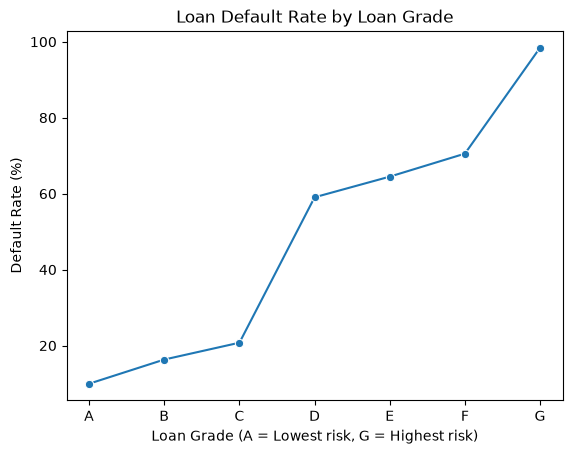

In [9]:
sns.lineplot(x=default_by_grade.index, y=default_by_grade.values, marker='o')
#Create a line plot to visualize the relationship between loan grade and loan default rates, with markers indicating the default rate for each loan grade.
plt.title('Loan Default Rate by Loan Grade')
plt.xlabel('Loan Grade (A = Lowest risk, G = Highest risk)')
plt.ylabel('Default Rate (%)')
plt.show()
#The title of the line plot indicates that it shows the loan default rate based on loan grade, with the x-axis labeled as 'Loan Grade (A = Lowest risk, G = Highest risk)' and the y-axis labeled as 'Default Rate (%)' to provide context for the visualization.


The line chart reflects the information the previous table gave. There is a steady rise from Grade A to C from around 10% to 21%, followed by a steep jumpt from 21% to 59%. The line then flattens from D to F, and a steep rise to Grade G which only rests on around 64 loans, showcasing that almost all loans defaulted

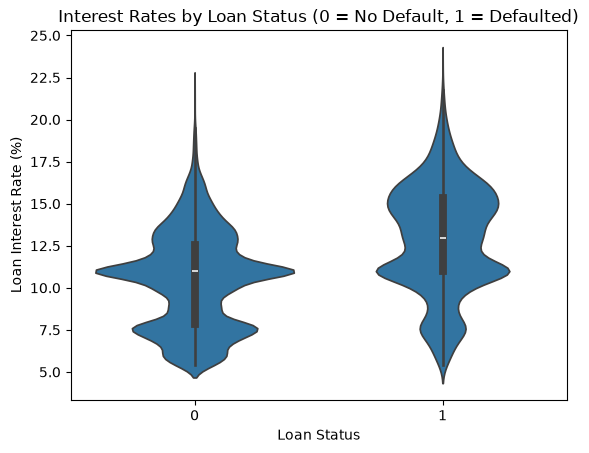

In [11]:
sns.violinplot(x='loan_status', y='loan_int_rate', data=df)
#Violin plot to visualize the distribution of loan interest rates for each loan grade, with the width representing the density of observations.
plt.title('Interest Rates by Loan Status (0 = No Default, 1 = Defaulted)')
plt.xlabel('Loan Status')
plt.ylabel('Loan Interest Rate (%)')
plt.show()

- Defaulted loans (1) tend to carry higher interest rates. 
- The median is about 13% for defaulted loans compared to that of around 11% for repaid loans (0). 
- The middle 50% of defualted loans sit at roughly 10.8% to 15.3%, compared to 7.7% to 12.9% for repaid loans. 
- The distributions heavily overlap, meaning interest rate is not decisive by itself. 
- The widening of the violin around 11% refelcts the missing interest rates that were filled with the median, showcasing a limitation of including the median values to fill in data. 

In [13]:
print(df.groupby('int_rate_missing')['loan_status'].agg(['mean', 'count']))
#Default rate and count of loans based on whether the interest rate is missing or not, to understand how missing interest rate information relates to loan default rates.
print(df.groupby('emp_length_missing')['loan_status'].agg(['mean', 'count']))
#Default rate and count of loans based on whether the employment length is missing or not, to understand how missing employment length information relates to loan default rates.


                      mean  count
int_rate_missing                 
0                 0.219922  29315
1                 0.207175   3094
                        mean  count
emp_length_missing                 
0                   0.215944  31522
1                   0.316798    887


31.7% of borrowers whose employment length was missing (1), defaulted on their loans, compared to 21.6% of borrowers with recorded employment length (0)



In contrast, 20.7% of borrowers with a missing interest rate defaulted, compared with 22.0% of borrowers with a recorded rate. The missing interest rates therefore seem to be unrelated to default 

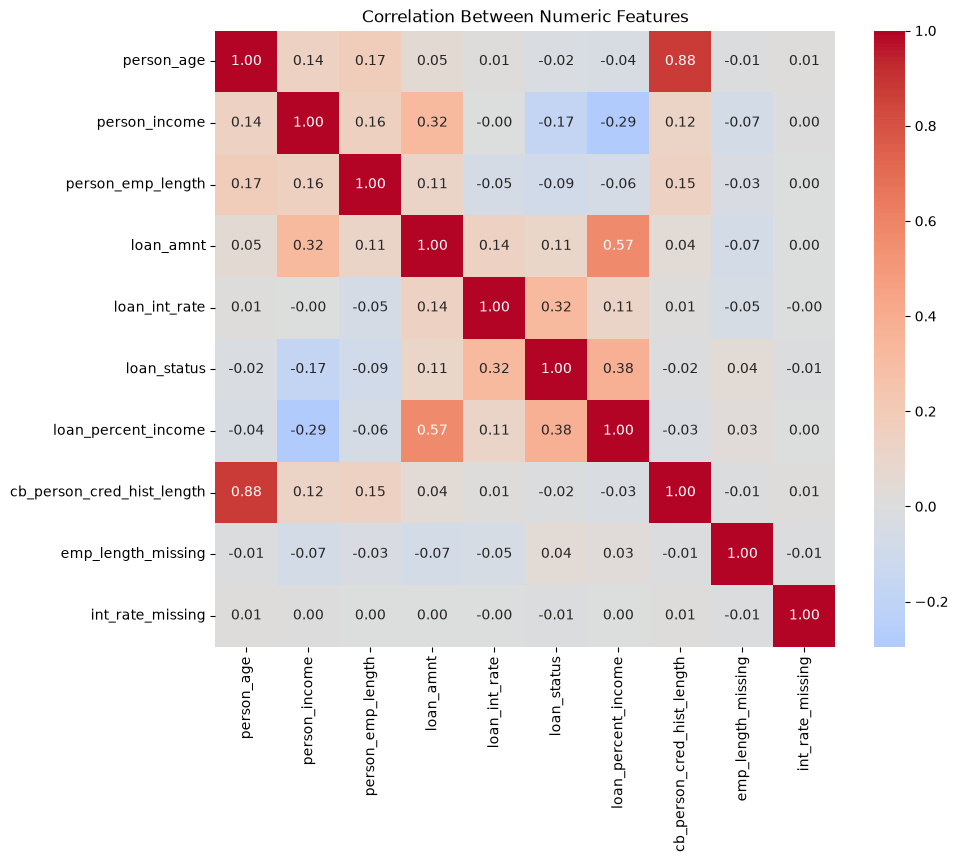

In [15]:
numeric_df = df.select_dtypes(include='number')
#Select only the numeric columns from the DataFrame for further analysis.
corr = numeric_df.corr()
#Calculate the correlation matrix for the numeric columns to understand the relationships between different numeric features in the
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
#Heatmap to visualize the correlation matrix, with annotations showing the correlation coefficients between numeric features, a color map to indicate the strength and direction of correlations, and a center value of 0 to distinguish between positive and negative correlations.
plt.title('Correlation Between Numeric Features')
plt.show()

Loan to incoem ratio and interest rate have the strongest correlation to loan status at (0.38) and (0.32), while income has a weak negative correlation at (-0.17). Age and credit history have almost no linear correlation with loan default. It is also important to note that 'person_age' and 'cb_person_cred_hist_length' are highly correlated with each other (0.88) highlighting how older borrowers have longer credit histories, meaning the two columns say nearly the same thing, making one of them redundant, which is important for further modelling. 